In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np
import seaborn as sns
import os
import json

In [2]:
%pwd

'/Users/lms/Documents/Forschung/textClust'

In [3]:
default_config = {
    "embClust": {
        "clean_interval": 100,
        "cluster_interval": 1000,
        "decay_rate": 0.0005,
        "min_num_mc": 1,
        "adaptive_threshold": 0,
        "radius": 0.3,
        "threshold_momentum": 0.5,
        "use_heuristic": 1,
        "time_gap": 100,
        "model": "sentenceTransformers",
    },
    "textClust": {
        "clean_interval": 100,
        "cluster_interval": 1000,
        "decay_rate": 0.0005,
        "min_num_mc": 1,
        "adaptive_threshold": 0,
        "radius": 0.3,
        "threshold_momentum": 0.5,
        "use_heuristic": 1,
        "time_gap": 100,
    }
}

In [4]:
dfs = []

for file in os.listdir("smac3_results_eval/embClust"):
    if file.endswith(".json"):
        df = pd.read_csv(os.path.join("smac3_results_eval/embClust", file))
        dfs.append(df)

for file in os.listdir("smac3_results_eval/textClust"):
    if file.endswith(".json"):
        df = pd.read_csv(os.path.join("smac3_results_eval/textClust", file))
        dfs.append(df)
        
smac3_results_eval = pd.concat(dfs, ignore_index=True)

smac3_results_eval["dataset"] = smac3_results_eval["dataset"].str.replace("examples/data/", "").str.replace(".json", "")
smac3_results_eval["dataset"] = smac3_results_eval["dataset"].str.replace("NTSO-T", "NTSO")
smac3_results_eval["is_test"] = smac3_results_eval["dataset"] == smac3_results_eval["loo_dataset"]

smac3_results_eval.head()

,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,...,num_clusters_true,avg_throughput,total_time,dataset,config,config_id,loo_dataset,seed,algorithm,is_test
0,0.918925,0.565117,1.717831,0.632709,0.643814,0.754762,0.561304,0.643814,0.610399,0.715661,...,10,1340.035118,19.086067,Semantic10-T,best_config_loo_Trends-T_seed_4.json,0,Trends-T,4,embClust,False
1,0.934958,0.626240,1.892395,0.674995,0.686036,0.831461,0.583909,0.686036,0.664858,0.941719,...,10,1370.308894,18.664405,Semantic10-T,best_config_loo_Trends-T_seed_4.json,1,Trends-T,4,embClust,False
2,0.938123,0.660540,1.888237,0.709888,0.716073,0.829633,0.629857,0.716073,0.695425,0.943167,...,10,1323.733062,19.321116,Semantic10-T,best_config_loo_Trends-T_seed_4.json,2,Trends-T,4,embClust,False
3,0.940203,0.678882,1.867220,0.714430,0.720322,0.820400,0.642007,0.720322,0.712305,0.940873,...,10,1314.354987,19.458974,Semantic10-T,best_config_loo_Trends-T_seed_4.json,3,Trends-T,4,embClust,False
4,0.940117,0.668382,1.887775,0.699099,0.708193,0.829431,0.617879,0.708193,0.702432,0.937494,...,10,1340.424858,19.080518,Semantic10-T,best_config_loo_Trends-T_seed_4.json,4,Trends-T,4,embClust,False


In [11]:
smac3_results_eval[smac3_results_eval["dataset"] == "Semantic40-T"].sort_values("adj_rand", ascending=False).head(10)

,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,...,num_clusters_true,avg_throughput,total_time,dataset,config,config_id,loo_dataset,seed,algorithm,is_test
7687,0.977742,0.582654,2.887125,0.746759,0.754817,0.802929,0.712145,0.754817,0.595945,0.977472,...,40,382.447134,97.085314,Semantic40-T,best_config_loo_SO-T_seed_4.json,8,SO-T,4,textClust,False
2140,0.975463,0.579757,2.871987,0.745623,0.755298,0.798719,0.716354,0.755298,0.592480,0.852988,...,40,56.228609,660.340006,Semantic40-T,best_config_loo_NTSO_seed_7.json,3,NTSO,7,embClust,False
5405,0.975849,0.574602,2.831949,0.749774,0.755326,0.787584,0.725607,0.755326,0.587087,0.968207,...,40,363.390559,102.176568,Semantic40-T,best_config_loo_Tweets-T_seed_8.json,0,Tweets-T,8,textClust,False
5513,0.975939,0.573857,2.821424,0.744207,0.750911,0.784657,0.719948,0.750911,0.586343,0.973838,...,40,412.700178,89.968461,Semantic40-T,best_config_loo_Semantic40-T_seed_8.json,4,Semantic40-T,8,textClust,True
9289,0.975505,0.572945,2.824387,0.739279,0.749867,0.785481,0.717342,0.749867,0.585567,0.976058,...,40,443.859810,83.652539,Semantic40-T,best_config_loo_NTSO_seed_8.json,4,NTSO,8,textClust,False
6045,0.977331,0.569776,2.885738,0.750918,0.756680,0.802543,0.715775,0.756680,0.583898,0.977939,...,40,412.740363,89.959702,Semantic40-T,best_config_loo_Semantic40-T_seed_4.json,5,Semantic40-T,4,textClust,True
9583,0.975698,0.565617,2.850083,0.729979,0.741338,0.792627,0.696283,0.741338,0.578348,0.971028,...,40,483.248397,76.834192,Semantic40-T,best_config_loo_News-T_seed_4.json,4,News-T,4,textClust,False
10858,0.974940,0.562978,2.921801,0.753591,0.762356,0.812572,0.717985,0.762356,0.575891,0.973934,...,40,248.593520,149.360289,Semantic40-T,best_config_loo_NTSO_seed_2.json,8,NTSO,2,textClust,False
11319,0.975517,0.562518,2.835960,0.741032,0.749059,0.788699,0.713213,0.749059,0.575336,0.974538,...,40,362.668113,102.380106,Semantic40-T,best_config_loo_NT_seed_8.json,1,NT,8,textClust,False
5514,0.975665,0.560811,2.796498,0.742438,0.746601,0.777725,0.717872,0.746601,0.573741,0.973042,...,40,268.568624,138.251444,Semantic40-T,best_config_loo_Semantic40-T_seed_8.json,5,Semantic40-T,8,textClust,True


In [31]:
pareto_configs = []

for c in os.listdir("smac3_results/embClust"):
    with open(f"smac3_results/embClust/{c}", "r") as f:
        configs = json.load(f)
        for id, config in enumerate(configs):
            config["config_id"] = id
            config["config"] = c
            config["algorithm"] = "embClust"
            pareto_configs.append(config)

for c in os.listdir("smac3_results/textClust"):
    with open(f"smac3_results/textClust/{c}", "r") as f:
        configs = json.load(f)
        for id, config in enumerate(configs):
            config["config_id"] = id
            config["config"] = c
            config["algorithm"] = "textClust"
            pareto_configs.append(config)

configs = pd.DataFrame(pareto_configs)

configs.head()

,adaptive_threshold,clean_interval,cluster_interval,decay_rate,min_num_mc,model,use_heuristic,min_weight,sigma,threshold_momentum,config_id,config,algorithm,time_gap,radius
0,1,267,1888,0.002884,20,minishlab,0,0.027619,1.039963,0.962155,0,best_config_loo_Trends-T_seed_4.json,embClust,NaN,NaN
1,1,426,4762,0.000160,26,minishlab,0,0.011415,1.098050,0.192808,1,best_config_loo_Trends-T_seed_4.json,embClust,NaN,NaN
2,1,327,3660,0.000188,25,minishlab,0,0.171731,2.090775,0.420138,2,best_config_loo_Trends-T_seed_4.json,embClust,NaN,NaN
3,1,363,2433,0.000213,26,minishlab,0,0.074644,2.052564,0.333753,3,best_config_loo_Trends-T_seed_4.json,embClust,NaN,NaN
4,1,325,3674,0.000214,26,minishlab,0,0.003455,1.569397,0.361464,4,best_config_loo_Trends-T_seed_4.json,embClust,NaN,NaN


In [32]:
smac3_results_eval[smac3_results_eval["config"] == "default"]

,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,adj_rand_final,mutual_info_final,adj_mutual_info_final,normalized_mutual_info_final,homogeneity_final,completeness_final,v_measure_final,fowlkes_mallows_final,num_evaluated_points,num_clusters_initial,num_clusters_final,num_clusters_true,avg_throughput,total_time,dataset,config,config_id,loo_dataset,seed,algorithm,is_test
3370,0.897053,0.039376,2.270991,0.264251,0.440144,0.997804,0.282345,0.440144,0.149328,0.900022,0.087353,2.268323,0.296724,0.461375,0.996632,0.300166,0.461375,0.224707,25576,13257,12705,10,65.740609,389.044158,Semantic10-T,default,0,none,none,embClust,False
3371,0.971690,0.128503,3.480464,0.438039,0.606827,0.967940,0.441947,0.606827,0.229067,0.966871,0.219399,3.340108,0.483359,0.626163,0.928906,0.472250,0.626163,0.251789,37130,15153,13998,40,63.271618,586.834998,Semantic40-T,default,0,none,none,embClust,False
3372,0.760596,0.017370,1.481247,0.177215,0.306956,0.981330,0.181932,0.306956,0.104494,0.808688,0.288290,1.473179,0.258550,0.379688,0.975985,0.235689,0.379688,0.457789,28887,13770,12033,5,69.599394,415.046716,Semantic5-T,default,0,none,none,embClust,False
3373,0.994862,0.446319,5.421921,0.654188,0.809273,0.993472,0.682695,0.809273,0.526782,0.995690,0.601990,5.370531,0.749876,0.846329,0.984056,0.742421,0.846329,0.634166,41429,10644,8821,419,46.989728,881.660777,NT,default,0,none,none,embClust,False
3374,0.992496,0.219881,5.254178,0.503506,0.740279,0.993253,0.590008,0.740279,0.340149,0.993079,0.335963,5.227670,0.596073,0.769582,0.988242,0.630153,0.769582,0.431570,61428,23887,21436,439,44.925008,1367.345339,NTS,default,0,none,none,embClust,False
3375,0.999585,0.334136,8.814123,0.151707,0.875297,0.999223,0.778718,0.875297,0.434317,0.999587,0.339947,8.813893,0.152624,0.875351,0.999196,0.778820,0.875351,0.438911,104135,99093,99074,10994,70.413658,1478.903433,NTSO,default,0,none,none,embClust,False
3376,0.999906,0.007154,9.215596,0.017868,0.881213,0.998659,0.788485,0.881213,0.035544,0.999906,0.007706,9.214679,0.018760,0.881212,0.998559,0.788546,0.881212,0.036209,123342,121004,120915,10573,66.059781,1867.126988,SO-T,default,0,none,none,embClust,False
3377,0.988837,0.306688,4.555834,0.577132,0.771195,0.992546,0.630570,0.771195,0.417365,0.990136,0.440951,4.541922,0.654805,0.798744,0.989516,0.669641,0.798744,0.520829,11109,4574,4143,152,67.174614,165.374972,News-T,default,0,none,none,embClust,False
3378,0.914475,0.233478,2.300189,0.232028,0.413738,0.998959,0.260897,0.413738,0.380409,0.918975,0.296621,2.298272,0.257130,0.432876,0.998127,0.276367,0.432876,0.435561,199992,111274,108182,10,53.106994,3765.831665,Trends-T,default,0,none,none,embClust,False
3379,0.991787,0.481551,4.917409,0.617622,0.781810,0.986653,0.647400,0.781810,0.544061,0.992538,0.577481,4.891200,0.672722,0.803211,0.981394,0.679787,0.803211,0.609286,30322,12311,11509,269,65.141793,465.476901,Tweets-T,default,0,none,none,embClust,False


In [33]:
def pareto_front(
    data: pd.DataFrame,
    x: str,
    y: str,
    minimize_x: bool = True,
    minimize_y: bool = True,
) -> pd.DataFrame:
    """
    Return the subset of `data` that is Pareto-optimal (non-dominated) in
    (x, y).
 
    A point A dominates point B if A is at least as good as B on both
    objectives and strictly better on at least one. Dominated points are
    dropped; the remaining rows form the Pareto front.
 
    Parameters
    ----------
    data : DataFrame with at least columns `x` and `y`.
    x, y : column names of the two objectives.
    minimize_x, minimize_y : whether lower values are "better" for that
        objective (set False to treat it as "higher is better").
 
    Returns
    -------
    DataFrame subset of `data` (original index preserved), sorted by `x`
    in the direction of improvement (ascending if minimize_x else
    descending).
    """
    if data.empty:
        return data.copy()
 
    sx = 1.0 if minimize_x else -1.0
    sy = 1.0 if minimize_y else -1.0
    vx = data[x].to_numpy(dtype=float) * sx
    vy = data[y].to_numpy(dtype=float) * sy
 
    # Sort by transformed x ascending, tie-break by transformed y ascending.
    order = np.lexsort((vy, vx))
 
    keep = np.zeros(len(data), dtype=bool)
    best_y = np.inf
    for idx in order:
        if vy[idx] < best_y:
            keep[idx] = True
            best_y = vy[idx]
        # else: dominated by an earlier point with equal-or-better x
        #       and equal-or-better y -> drop
 
    front = data[keep]
    return front.sort_values(x, ascending=minimize_x)

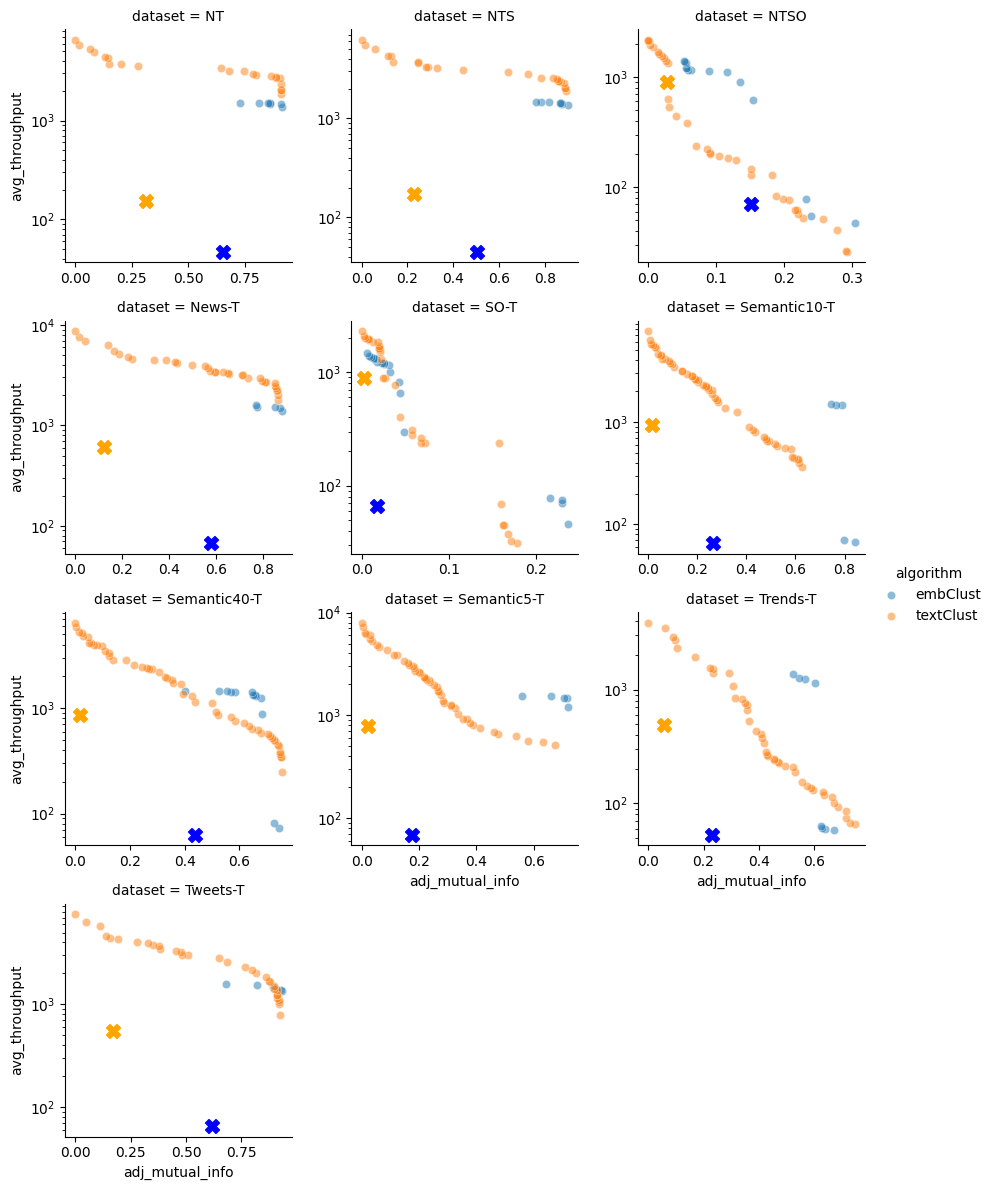

In [34]:
# Question: How do the algorithms perform on the datasets? Consider throughput and AMI

# Consider the train set first. Make sure to exclude the default config. Show all configurations (no means)
df = smac3_results_eval[(smac3_results_eval["is_test"] == False) & (smac3_results_eval["config"] != "default")]

df_just_pareto = df.groupby(["dataset", "algorithm"]).apply(lambda x: pareto_front(x, "adj_mutual_info", "avg_throughput", minimize_x=False, minimize_y=False)).reset_index()

g = sns.FacetGrid(df_just_pareto, col="dataset", hue="algorithm", sharex=False, sharey=False, col_wrap=3)
g.map(sns.scatterplot, "adj_mutual_info", "avg_throughput", alpha=0.5).add_legend()
g.set(yscale="log")

#Add default config to the plot
df_default = smac3_results_eval[smac3_results_eval["config"] == "default"]
for ax, ds in zip(g.axes.flat, df_just_pareto["dataset"].unique()):
    default_point_embClust = df_default[(df_default["dataset"] == ds) & (df_default["algorithm"] == "embClust")]
    if not default_point_embClust.empty:
        ax.scatter(default_point_embClust["adj_mutual_info"], default_point_embClust["avg_throughput"], color="blue", label="default", marker="X", s=100)
    default_point_textClust = df_default[(df_default["dataset"] == ds) & (df_default["algorithm"] == "textClust")]
    if not default_point_textClust.empty:
        ax.scatter(default_point_textClust["adj_mutual_info"], default_point_textClust["avg_throughput"], color="orange", label="default", marker="X", s=100)
        
# TODO Why is the AMI on NTSO and SO-T so bad?

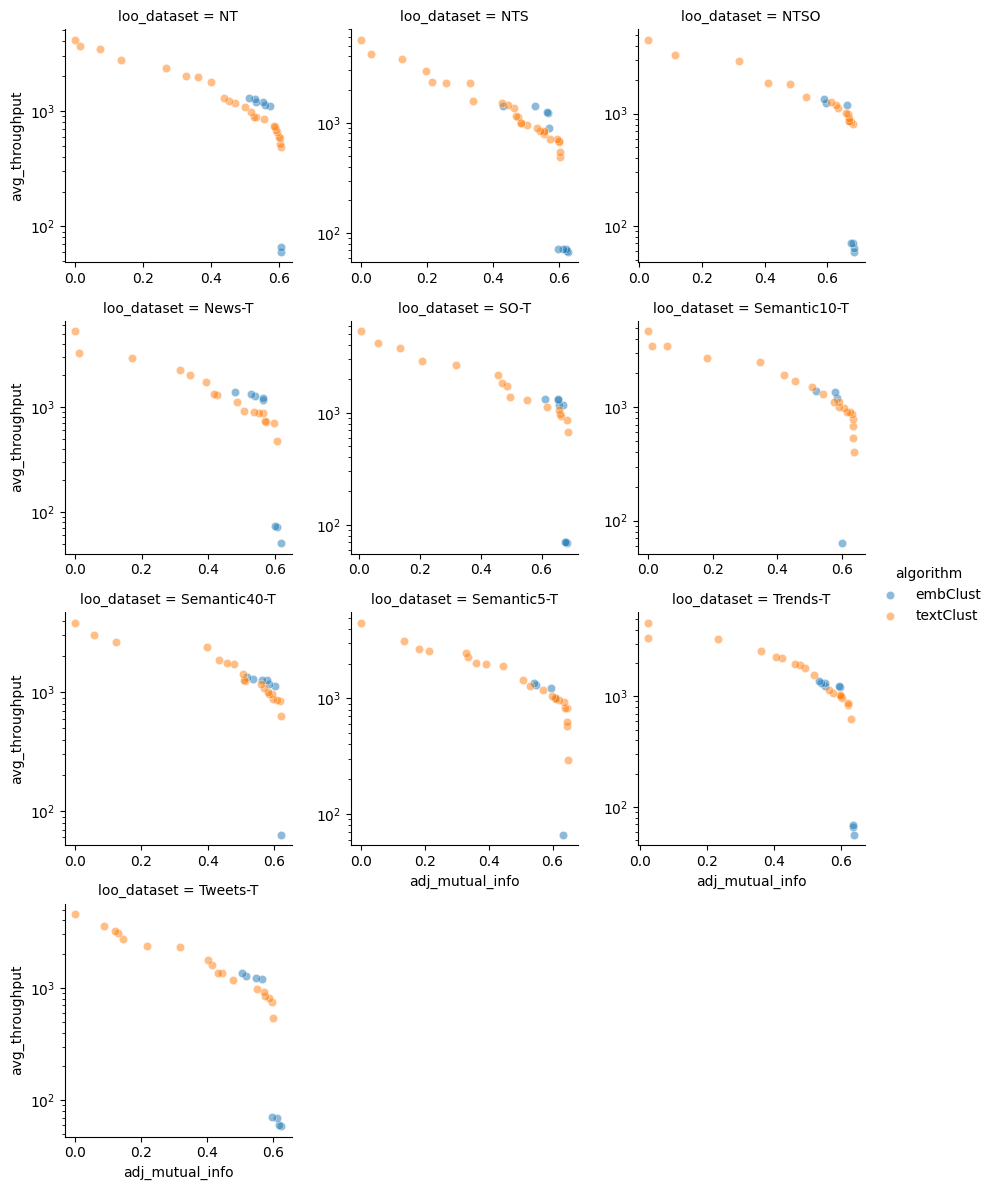

In [35]:
# Compare average performance without test set #TODO This isnt correct yet

df_train = smac3_results_eval[(smac3_results_eval["is_test"] == False) & (smac3_results_eval["config"] != "default")]
df_avg = df_train
df_avg = df_avg.groupby(["algorithm", "config", "config_id", "loo_dataset"])
df_avg = df_avg.agg({"adj_mutual_info": "mean", "avg_throughput": "mean"})
df_avg = df_avg.reset_index()

df_just_pareto = df_avg
df_just_pareto = df_just_pareto.groupby(["algorithm", "loo_dataset"])
df_just_pareto = df_just_pareto.apply(lambda x: pareto_front(x, "adj_mutual_info", "avg_throughput", minimize_x=False, minimize_y=False))
df_just_pareto = df_just_pareto.reset_index()

g = sns.FacetGrid(df_just_pareto, col="loo_dataset", hue="algorithm", sharex=False, sharey=False, col_wrap=3)
g.map(sns.scatterplot, "adj_mutual_info", "avg_throughput", alpha=0.5).add_legend()
g.set(yscale="log")

# df_just_pareto = pareto_front(df_avg, "adj_mutual_info_final", "avg_throughput", minimize_x=False, minimize_y=False).reset_index()
# sns.scatterplot(data=df_just_pareto, x="adj_mutual_info_final", y="avg_throughput", hue="algorithm", marker = "D", s=80, alpha=0.5)

# #Add default config to the plot
# df_default = smac3_results_eval[smac3_results_eval["config"] == "default"].groupby("algorithm").agg({"adj_mutual_info_final": "mean", "avg_throughput": "mean"}).reset_index()
# sns.scatterplot(data=df_default, x="adj_mutual_info_final", y="avg_throughput", hue="algorithm", marker = "X", s=100, alpha=0.5)

/Users/lms/Documents/Forschung/textClust/.textClustEnv/lib/python3.11/site-packages/seaborn/axisgrid.py:718: UserWarning: Using the boxplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


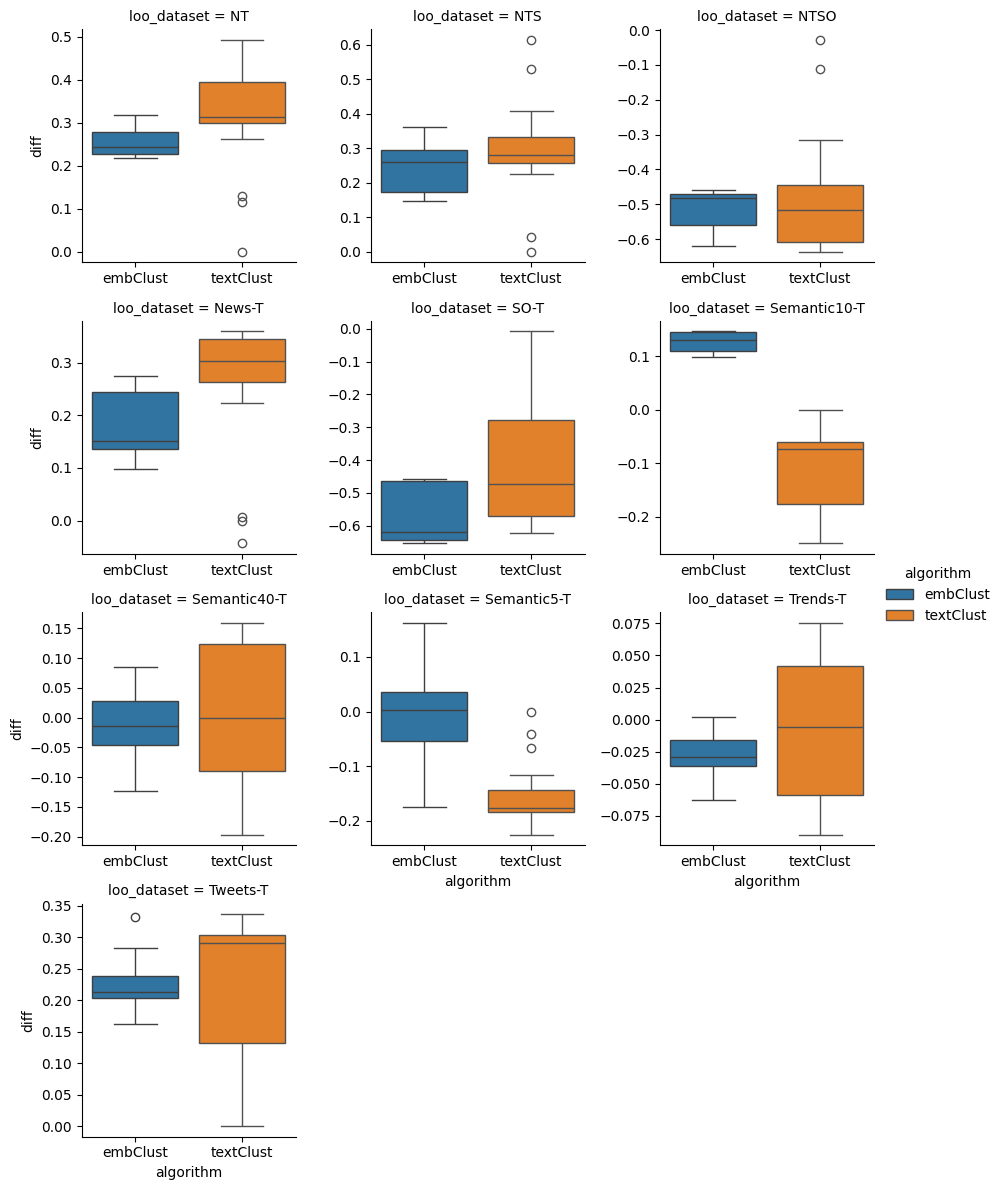

In [36]:
df_test = smac3_results_eval[(smac3_results_eval["is_test"] == True) & (smac3_results_eval["config"] != "default")]
df_test = df_test[["algorithm", "config", "config_id", "loo_dataset", "adj_mutual_info", "avg_throughput"]]


df_test = df_just_pareto.merge(df_test, on=["algorithm", "config", "config_id", "loo_dataset"], suffixes=("_train", "_test"))
df_test["diff"] = df_test["adj_mutual_info_test"] - df_test["adj_mutual_info_train"]

g = sns.FacetGrid(df_test, col="loo_dataset", hue="algorithm", sharex=False, sharey=False, col_wrap=3)
g.map(sns.boxplot, "algorithm", "diff").add_legend()




#df_long = pd.melt(df_test, id_vars=["algorithm", "config", "config_id", "loo_dataset"], value_vars=["adj_mutual_info_train", "avg_throughput_train", "adj_mutual_info_test", "avg_throughput_test"], var_name="metric", value_name="value")

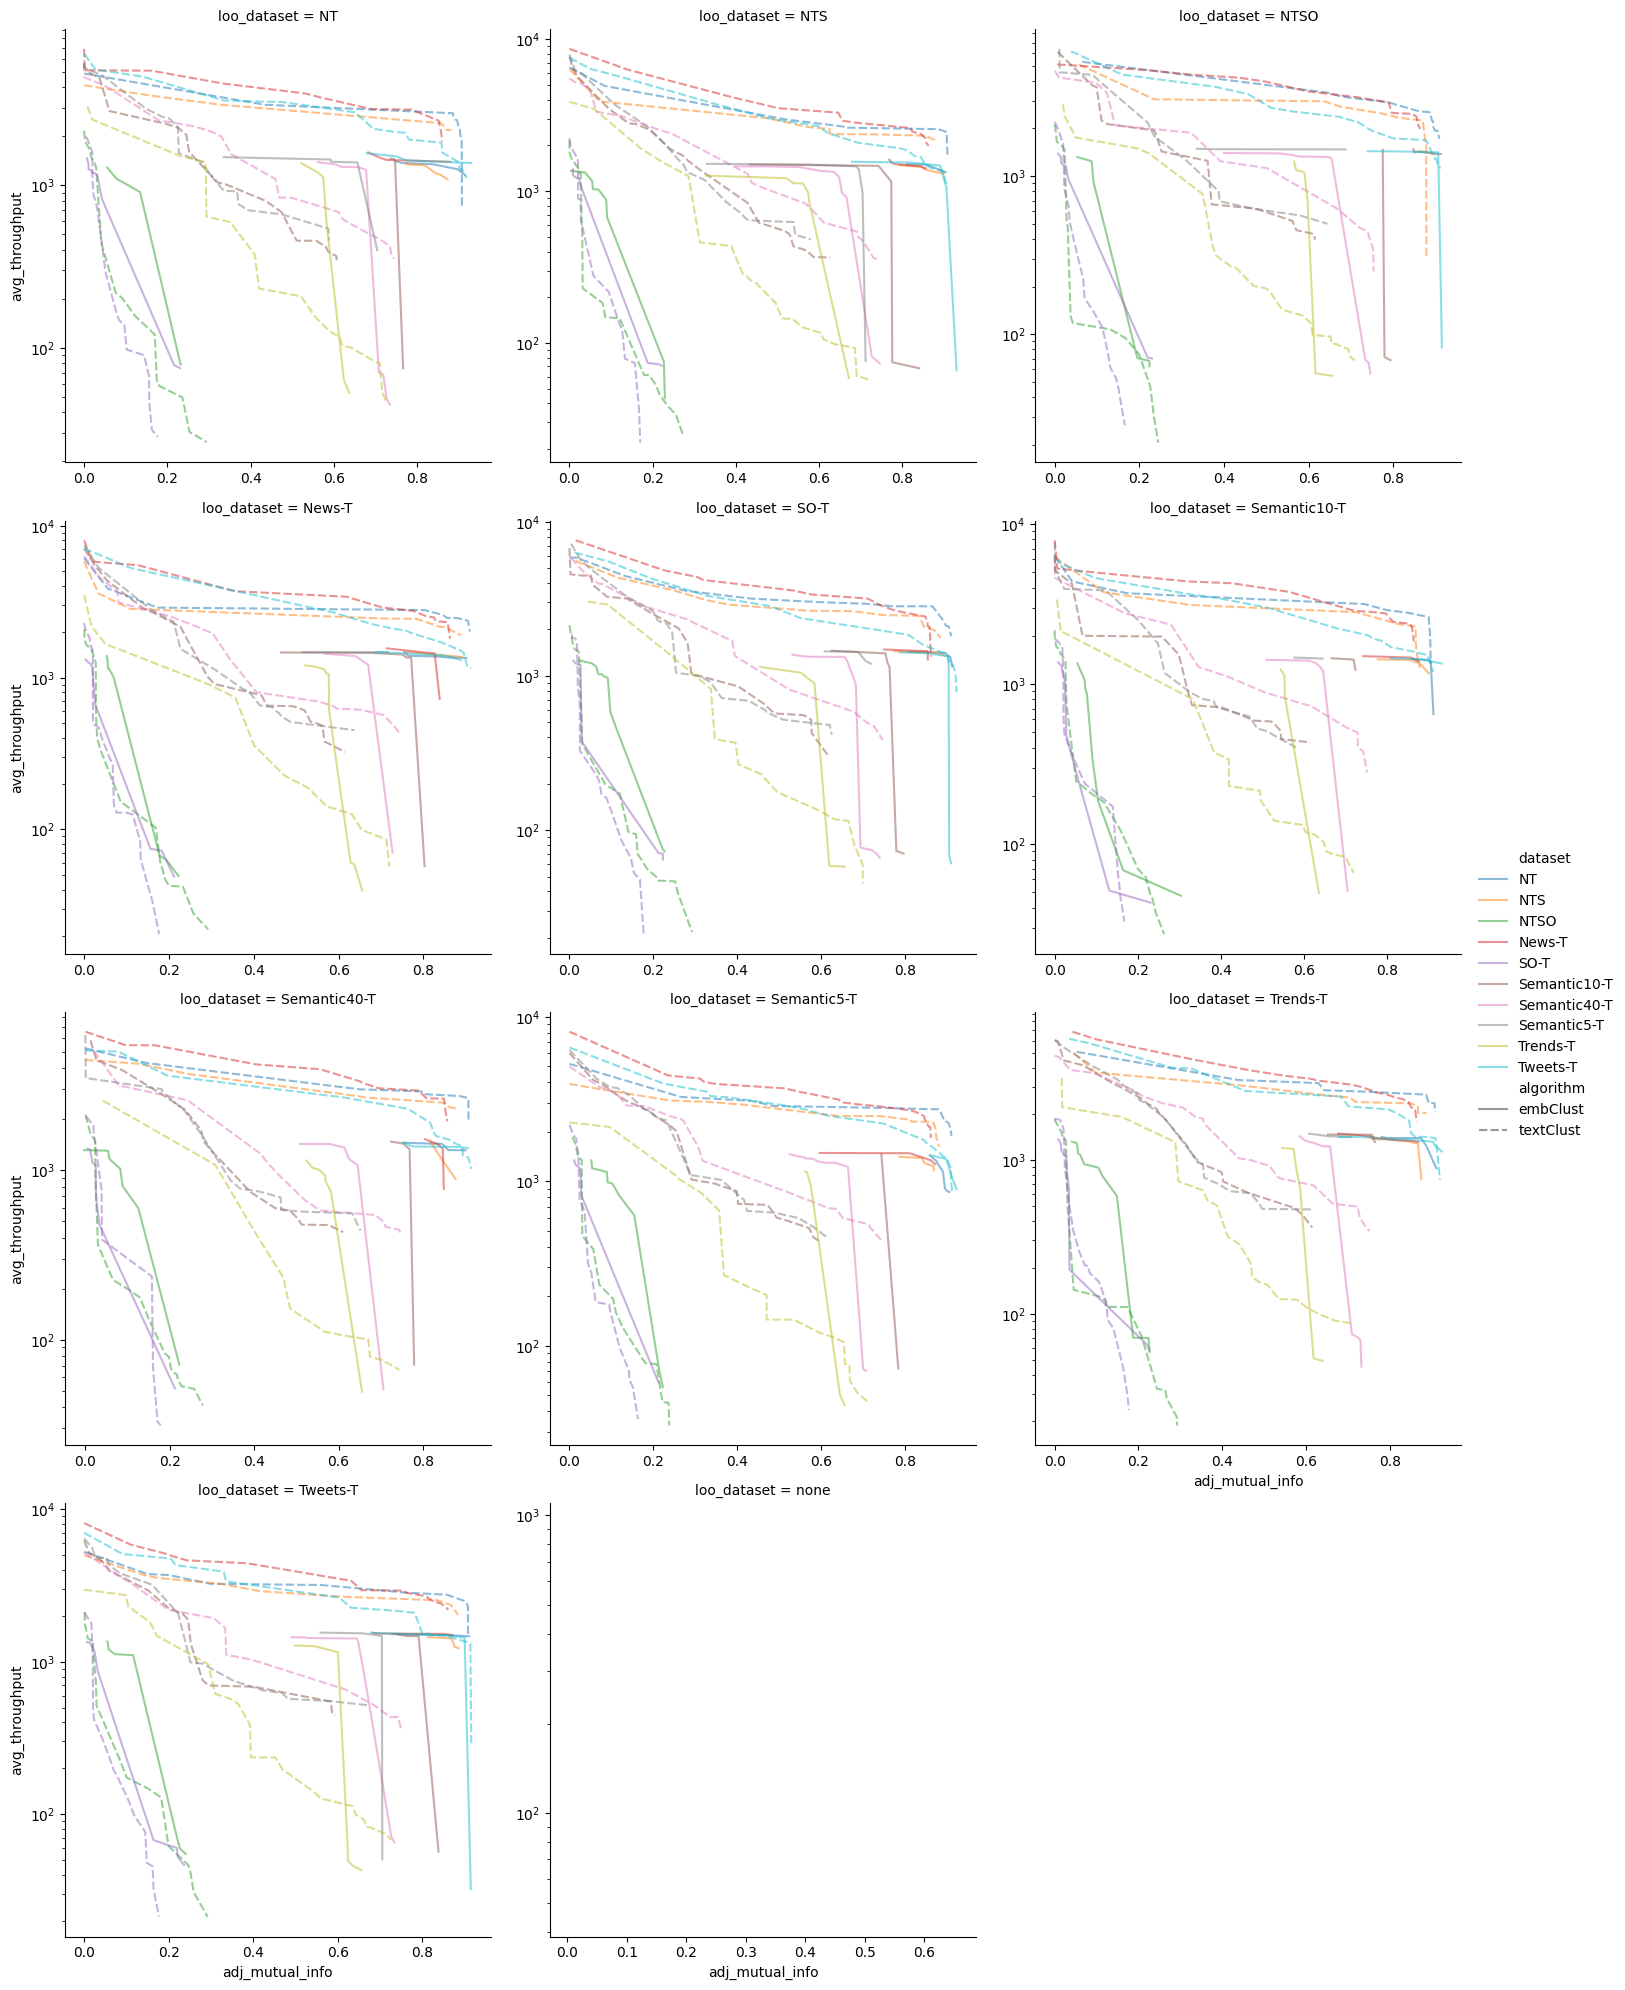

In [37]:
df = smac3_results_eval.copy()

df_just_pareto = df.groupby(["loo_dataset", "dataset", "algorithm"]).apply(lambda x: pareto_front(x, "adj_mutual_info", "avg_throughput", minimize_x=False, minimize_y=False)).reset_index()

g = sns.relplot(
    data=df_just_pareto,
    x="adj_mutual_info", y="avg_throughput",
    col="loo_dataset", hue="dataset", style="algorithm",
    col_wrap=3, kind="line",
    facet_kws={"sharex": False, "sharey": False},
    alpha=0.5
)

# g = sns.FacetGrid(df_just_pareto, col="loo_dataset", hue="dataset", sharex=False, sharey=False, col_wrap=3)
# g.map_dataframe(sns.scatterplot, x="adj_mutual_info", y="avg_throughput", style="is_test", alpha=0.5)
# g.add_legend()
# Log scale
g.set(yscale="log")

In [38]:
# Compute hypervolume 
from pymoo.indicators.hv import Hypervolume

hv = Hypervolume(ref_point=np.array([-0.5, 0]))

df = smac3_results_eval.copy()
df["log_avg_throughput"] = np.log(df["avg_throughput"])
df = df.groupby(["loo_dataset", "dataset", "algorithm"]).apply(lambda x: hv(-x[["adj_mutual_info", "log_avg_throughput"]])).reset_index()

df.head()

,loo_dataset,dataset,algorithm,0
0,NT,NT,embClust,2.992023
1,NT,NT,textClust,3.229564
2,NT,NTS,embClust,2.685326
3,NT,NTS,textClust,2.974360
4,NT,NTSO,embClust,0.000000


In [39]:
"""
Compare Twitter cluster datasets in terms of TF-IDF homogeneity and separation.

Each dataset is expected to be a JSON-lines file where each line has:
    - "clusterNo" (or "topic") : cluster id
    - "tweets"                 : tweet text (already tokenizable / whitespace-split)

For every dataset we compute, per document, TF-IDF vectors, then aggregate to
cluster level to answer two questions:

    1. How HOMOGENOUS is each cluster? (do the tweets in a cluster look alike?)
    2. How DIFFERENT are the clusters from one another? (do clusters overlap?)

Metrics per dataset:
    - avg_intra_cluster_similarity : mean cosine similarity between tweets
                                     within the same cluster (homogeneity)
    - std_intra_cluster_similarity : how consistent homogeneity is across clusters
    - avg_inter_cluster_similarity : mean cosine similarity between cluster
                                     centroids (separation; lower = more distinct)
    - separation_gap               : intra - inter (higher = better formed clusters)
    - silhouette_score             : standard clustering quality metric (-1..1)
    - davies_bouldin_index         : lower is better
    - calinski_harabasz_index      : higher is better
    - avg_word_entropy             : average Shannon entropy of the word-frequency
                                     distribution within a cluster (lower = more
                                     concentrated/homogenous vocabulary)

Run:
    python compare_cluster_datasets.py
"""

import json
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import entropy


def load_dataset(path):
    """Load a JSON-lines dataset into {clusterNo: [tweet_text, ...]}."""
    clusters_text = {}
    with open(path, "r") as file:
        for l in file:
            l = l.strip()
            if not l:
                continue
            item = json.loads(l)
            cluster_no = item.get("clusterNo", None)
            if cluster_no is None:
                cluster_no = item.get("topic", 0)
            text = item.get("tweets", "")
            clusters_text.setdefault(cluster_no, []).append(text)
    return clusters_text


def analyze_dataset(clusters_text, dataset_name, min_df=1, max_features=20000):
    """Compute TF-IDF based homogeneity/separation metrics for one dataset."""
    docs, labels = [], []
    for cluster_id, texts in clusters_text.items():
        for t in texts:
            if t and t.strip():
                docs.append(t)
                labels.append(cluster_id)
    labels = np.array(labels)

    if len(docs) < 3 or len(set(labels)) < 2:
        print(f"[{dataset_name}] skipped: not enough documents/clusters")
        return None

    vectorizer = TfidfVectorizer(
        min_df=min_df, max_features=max_features, stop_words="english"
    )
    X = vectorizer.fit_transform(docs)

    unique_labels = sorted(set(labels))
    centroids = []
    intra_sims = {}
    cluster_sizes = {}
    word_entropies = []

    for cl in unique_labels:
        idx = np.where(labels == cl)[0]
        cluster_sizes[cl] = len(idx)
        sub = X[idx]

        # centroid (mean TF-IDF vector) for this cluster
        centroids.append(np.asarray(sub.mean(axis=0)).flatten())

        # intra-cluster homogeneity: mean pairwise cosine similarity
        if len(idx) > 1:
            sims = cosine_similarity(sub)
            n = sims.shape[0]
            off_diag_sum = sims.sum() - np.trace(sims)
            intra_sims[cl] = off_diag_sum / (n * (n - 1))
        else:
            intra_sims[cl] = np.nan

        # vocabulary concentration (entropy of word weight distribution)
        word_sums = np.asarray(sub.sum(axis=0)).flatten()
        word_sums = word_sums[word_sums > 0]
        if word_sums.sum() > 0:
            p = word_sums / word_sums.sum()
            word_entropies.append(entropy(p))
        else:
            word_entropies.append(np.nan)

    # inter-cluster separation: mean pairwise cosine similarity between centroids
    centroid_matrix = np.vstack(centroids)
    if centroid_matrix.shape[0] > 1:
        inter_sim_matrix = cosine_similarity(centroid_matrix)
        n_c = inter_sim_matrix.shape[0]
        off_diag_sum = inter_sim_matrix.sum() - np.trace(inter_sim_matrix)
        avg_inter_sim = off_diag_sum / (n_c * (n_c - 1))
    else:
        avg_inter_sim = np.nan

    # standard clustering-quality metrics (need dense matrix; fine for a few
    # thousand docs, subsample if your dataset is huge)
    try:
        X_dense = X.toarray()
        #sil = silhouette_score(X_dense, labels, metric="cosine")
        #db = davies_bouldin_score(X_dense, labels)
        #ch = calinski_harabasz_score(X_dense, labels)
    except Exception as e:
        print(f"[{dataset_name}] sklearn metric computation failed: {e}")
        sil, db, ch = np.nan, np.nan, np.nan

    avg_intra_sim = float(np.nanmean(list(intra_sims.values())))
    std_intra_sim = float(np.nanstd(list(intra_sims.values())))

    return {
        "dataset": dataset_name,
        "n_clusters": len(unique_labels),
        "n_documents": len(docs),
        "vocab_size": X.shape[1],
        "avg_cluster_size": float(np.mean(list(cluster_sizes.values()))),
        "avg_intra_cluster_similarity": avg_intra_sim,
        "std_intra_cluster_similarity": std_intra_sim,
        "avg_inter_cluster_similarity": float(avg_inter_sim),
        "separation_gap": avg_intra_sim - float(avg_inter_sim),
        #"silhouette_score": sil,
        #"davies_bouldin_index": db,
        #"calinski_harabasz_index": ch,
        "avg_word_entropy": float(np.nanmean(word_entropies)),
    }


if __name__ == "__main__":
    # Add every dataset you want to compare here.
    dataset_folder = "examples/data/"
    dataset_paths = {}
    for file in os.listdir(dataset_folder):
        if file.endswith(".json"):
            dataset_name = file.replace(".json", "")
            dataset_paths[dataset_name] = os.path.join(dataset_folder, file)

    results = []
    for name, path in dataset_paths.items():
        try:
            print(f"[{name}] loading dataset from {path}...")
            clusters_text = load_dataset(path)
        except FileNotFoundError:
            print(f"[{name}] file not found at {path}, skipping")
            continue
        res = analyze_dataset(clusters_text, name)
        if res:
            results.append(res)

    df = pd.DataFrame(results)
    if not df.empty:
        df = df.sort_values("separation_gap", ascending=False).reset_index(drop=True)
        pd.set_option("display.width", 160)
        pd.set_option("display.max_columns", None)
        print("\n=== Cluster homogeneity / separation comparison ===")
        print(df.to_string(index=False))
        df.to_csv("cluster_comparison.csv", index=False)
        print("\nSaved to cluster_comparison.csv")
    else:
        print("No datasets produced results.")
        
dataset_statistics = df.copy()

[NT] loading dataset from examples/data/NT.json...
[Semantic5-T_sorted] loading dataset from examples/data/Semantic5-T_sorted.json...
[NTSO-T] loading dataset from examples/data/NTSO-T.json...
[Semantic10-T] loading dataset from examples/data/Semantic10-T.json...
[NTS] loading dataset from examples/data/NTS.json...
[Tweets-T] loading dataset from examples/data/Tweets-T.json...
[News-T] loading dataset from examples/data/News-T.json...
[Semantic5-T] loading dataset from examples/data/Semantic5-T.json...
[Semantic40-T] loading dataset from examples/data/Semantic40-T.json...
[Trends-T] loading dataset from examples/data/Trends-T.json...
[Trends-T_modified] loading dataset from examples/data/Trends-T_modified.json...
[SO-T] loading dataset from examples/data/SO-T.json...

=== Cluster homogeneity / separation comparison ===
           dataset  n_clusters  n_documents  vocab_size  avg_cluster_size  avg_intra_cluster_similarity  std_intra_cluster_similarity  avg_inter_cluster_similarity  sepa

In [41]:
smac3_results_eval.head()

,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,adj_rand_final,mutual_info_final,adj_mutual_info_final,normalized_mutual_info_final,homogeneity_final,completeness_final,v_measure_final,fowlkes_mallows_final,num_evaluated_points,num_clusters_initial,num_clusters_final,num_clusters_true,avg_throughput,total_time,dataset,config,config_id,loo_dataset,seed,algorithm,is_test
0,0.918925,0.565117,1.717831,0.632709,0.643814,0.754762,0.561304,0.643814,0.610399,0.715661,0.279790,0.977837,0.555013,0.556532,0.429632,0.789822,0.556532,0.477568,25576,476,51,10,1340.035118,19.086067,Semantic10-T,best_config_loo_Trends-T_seed_4.json,0,Trends-T,4,embClust,False
1,0.934958,0.626240,1.892395,0.674995,0.686036,0.831461,0.583909,0.686036,0.664858,0.941719,0.733972,1.761669,0.819086,0.819382,0.774024,0.870387,0.819382,0.775809,25576,541,26,10,1370.308894,18.664405,Semantic10-T,best_config_loo_Trends-T_seed_4.json,1,Trends-T,4,embClust,False
2,0.938123,0.660540,1.888237,0.709888,0.716073,0.829633,0.629857,0.716073,0.695425,0.943167,0.739845,1.783476,0.827029,0.827428,0.783605,0.876443,0.827428,0.780630,25576,305,38,10,1323.733062,19.321116,Semantic10-T,best_config_loo_Trends-T_seed_4.json,2,Trends-T,4,embClust,False
3,0.940203,0.678882,1.867220,0.714430,0.720322,0.820400,0.642007,0.720322,0.712305,0.940873,0.729703,1.754709,0.814864,0.815245,0.770965,0.864920,0.815245,0.771800,25576,289,33,10,1314.354987,19.458974,Semantic10-T,best_config_loo_Trends-T_seed_4.json,3,Trends-T,4,embClust,False
4,0.940117,0.668382,1.887775,0.699099,0.708193,0.829431,0.617879,0.708193,0.702432,0.937494,0.716770,1.749355,0.814391,0.814701,0.768613,0.866668,0.814701,0.761574,25576,464,26,10,1340.424858,19.080518,Semantic10-T,best_config_loo_Trends-T_seed_4.json,4,Trends-T,4,embClust,False


In [57]:
df = smac3_results_eval.copy()

df_just_pareto = df.groupby(["algorithm", "dataset"])
df_just_pareto = df_just_pareto.apply(lambda x: pareto_front(x, "adj_mutual_info", "avg_throughput", minimize_x=False, minimize_y=False))
df_just_pareto = df_just_pareto.reset_index()

from pymoo.indicators.hv import Hypervolume

ind = Hypervolume(ref_point=np.array([-0.3, 0]))

result = []

for d in df_just_pareto["dataset"].unique():
    min_point = df_just_pareto[df_just_pareto["dataset"] == d][["adj_mutual_info", "avg_throughput"]].min().to_numpy()
    max_point = df_just_pareto[df_just_pareto["dataset"] == d][["adj_mutual_info", "avg_throughput"]].max().to_numpy()
    scaled_df = df_just_pareto[df_just_pareto["dataset"] == d].copy()
    scaled_df["avg_throughput"] = (scaled_df["avg_throughput"] - min_point[1]) / (max_point[1] - min_point[1])
    
    for a in scaled_df["algorithm"].unique():
        subset = scaled_df[scaled_df["algorithm"] == a]
        hv = ind(-subset[["adj_mutual_info", "avg_throughput"]].to_numpy())
        result.append({"dataset": d, "algorithm": a, "hypervolume": hv})
        
df = pd.DataFrame(result)
df_wide = df.pivot(index="dataset", columns="algorithm", values="hypervolume").reset_index()
df_wide["diff"] = df_wide["embClust"] - df_wide["textClust"]
hypervolume_comparison = df_wide.copy()

Wilcoxon test statistic: 11.0, p-value: 0.10546875


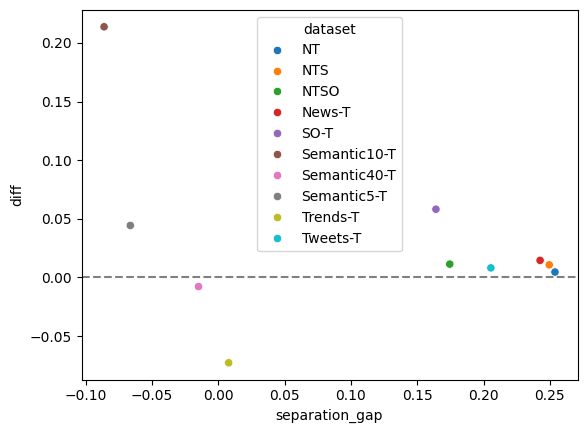

In [61]:
max_ami = smac3_results_eval.groupby(["dataset", "algorithm"])["adj_mutual_info"].max().reset_index()
max_ami_wide = max_ami.pivot(index="dataset", columns="algorithm", values="adj_mutual_info").reset_index()
max_ami_wide["diff"] = max_ami_wide["embClust"] - max_ami_wide["textClust"]

dataset_statistics.loc[dataset_statistics["dataset"] == "NTSO-T", "dataset"] = "NTSO"
df = dataset_statistics.merge(max_ami_wide, on="dataset", how="right")
sns.scatterplot(data=df, x="separation_gap", y="diff", hue="dataset")
# Add horizontal line at y=0
plt.axhline(0, color="gray", linestyle="--")

# Make statistical test
from scipy.stats import wilcoxon
wilco_test = wilcoxon(df["embClust"], df["textClust"])
print(f"Wilcoxon test statistic: {wilco_test.statistic}, p-value: {wilco_test.pvalue}")

In [61]:
from sklearn.metrics.pairwise import cosine_similarity
clusters = {}
clusters_text = {}
words = set()
with open("examples/data/Semantic40-T.json", "r") as file:
    for l in file:
        item = json.loads(l)
        clusterNo = item.get("clusterNo", None) or item.get("topic", 0)
        text = item.get("tweets", "")
        if clusterNo not in clusters:
            clusters[clusterNo] = {}
            clusters_text[clusterNo] = []
        clusters_text[clusterNo].append(text)
        for w in text.split():
            clusters[clusterNo][w] = clusters[clusterNo].get(w, 0) + 1
            words.add(w)

# Term frequency matrix
tf_matrix = np.zeros((len(clusters), len(words)))
word_list = list(words)
word_index = {word: idx for idx, word in enumerate(word_list)}
for i, (clusterNo, word_freq) in enumerate(clusters.items()):
    for w, v in word_freq.items():
        tf_matrix[i, word_index[w]] = v

# Inverse document frequency
num_clusters = len(clusters)
idf = np.log(num_clusters / (np.sum(tf_matrix > 0, axis=0)))

#TF-IDF matrix
tf_idf_matrix = tf_matrix * idf

#Cosine similarity matrix
similarity_matrix = cosine_similarity(tf_idf_matrix)    

avg_similarities = []

for c, t in clusters_text.items():
    idx = np.random.choice(len(t), size=min(1000, len(t)), replace=False)
    t = [t[i] for i in idx]   
    tf_matrix_c = np.zeros((len(t), len(words)))
    for i, text in enumerate(t):
        for w in text.split():
            if w in word_index:
                tf_matrix_c[i, word_index[w]] += 1
    tf_idf_matrix_c = tf_matrix_c * idf
    similarity_c = cosine_similarity(tf_idf_matrix_c)
    avg_similarity = np.mean(similarity_c[np.triu_indices_from(similarity_c, k=1)])
    avg_similarities.append(avg_similarity)

print(f"Average similarity inter clusters: {np.mean(similarity_matrix[np.triu_indices_from(similarity_matrix, k=1)]):.4f}")
print(f"Variance similarity inter clusters: {np.var(similarity_matrix[np.triu_indices_from(similarity_matrix, k=1)]):.4f}")
print(f"Average similarity intra clusters: {np.mean(avg_similarities):.4f}")
print(f"Variance in similarity intra all clusters: {np.var(avg_similarities):.4f}")

Average similarity inter clusters: 0.0171
Variance similarity inter clusters: 0.0020
Average similarity intra clusters: 0.0473
Variance in similarity intra all clusters: 0.0007


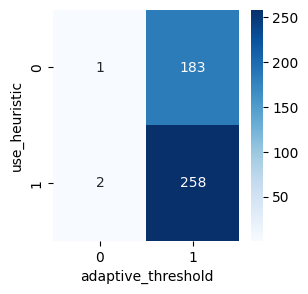

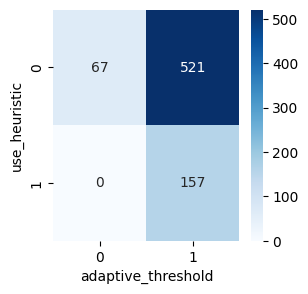

In [55]:
# Question: How do the configurations differ?

df = configs.copy()
df = df[df["algorithm"] == "embClust"]

heatmap_data = df.groupby(["use_heuristic", "adaptive_threshold"]).size().unstack(fill_value=0)
g = sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="Blues")

#Decrease plot size
plt.gcf().set_size_inches(3, 3)
plt.show()

df = configs.copy()
df = df[df["algorithm"] == "textClust"]

heatmap_data = df.groupby(["use_heuristic", "adaptive_threshold"]).size().unstack(fill_value=0)
g = sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="Blues")

#Decrease plot size
plt.gcf().set_size_inches(3, 3)
plt.show()


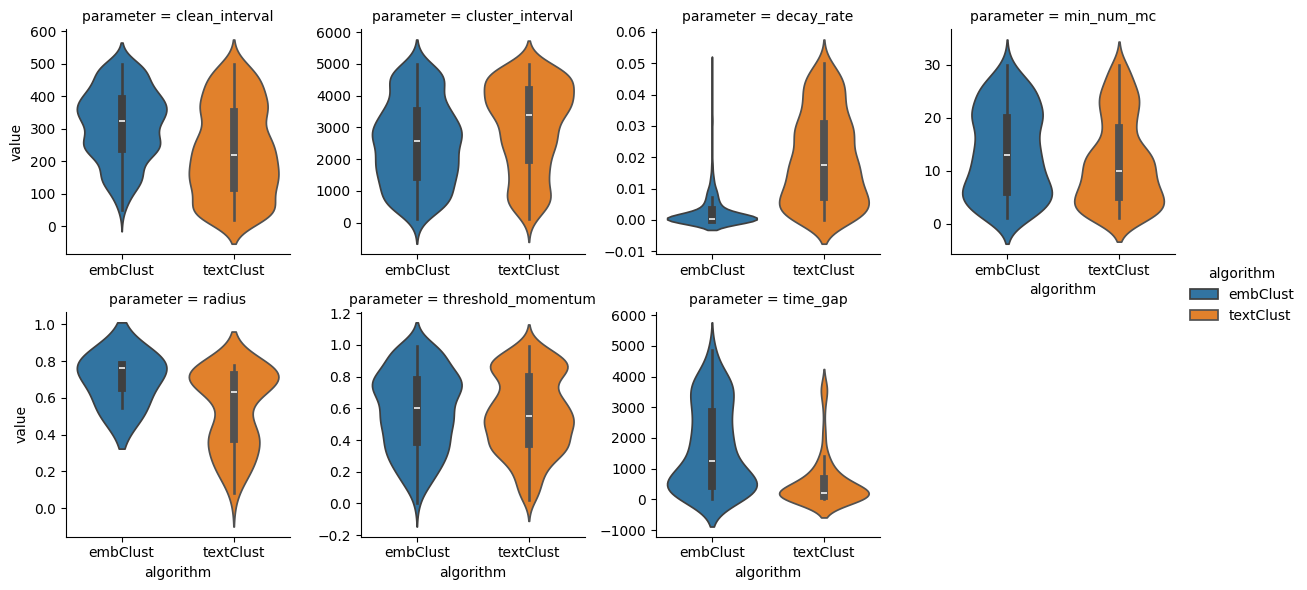

Parameter: clean_interval, Mann-Whitney U test p-value: 0.0000
Parameter: cluster_interval, Mann-Whitney U test p-value: 0.0000
Parameter: decay_rate, Mann-Whitney U test p-value: 0.0000
Parameter: min_num_mc, Mann-Whitney U test p-value: 0.0001
Parameter: radius, Mann-Whitney U test p-value: 0.0922
Parameter: threshold_momentum, Mann-Whitney U test p-value: 0.1914
Parameter: time_gap, Mann-Whitney U test p-value: 0.0000


In [69]:
numeric_parameters = ["clean_interval", "cluster_interval", "decay_rate", "min_num_mc", "radius", "threshold_momentum", "time_gap"]

df = configs.copy()
df_long = df.melt(id_vars=["algorithm", "config", "config_id"], value_vars=numeric_parameters, var_name="parameter", value_name="value")

g = sns.FacetGrid(df_long, col="parameter", hue="algorithm", sharex=False, sharey=False, col_wrap=4)
g.map_dataframe(sns.violinplot, x="algorithm", y="value").add_legend()
plt.show()

# Test statistical differences between the two algorithms for each parameter
for param in numeric_parameters:
    df_param = df_long[df_long["parameter"] == param].dropna(subset=["value"])
    from scipy.stats import mannwhitneyu
    stat, p = mannwhitneyu(df_param[df_param["algorithm"] == "embClust"]["value"], df_param[df_param["algorithm"] == "textClust"]["value"])
    print(f"Parameter: {param}, Mann-Whitney U test p-value: {p:.4f}")